# Лабораторная работа №1. Регрессия качества вина

**Предмет:** Машинное обучение. **Данные:** UCI Wine Quality, красное вино.

**Цель:** пройти полный цикл решения задачи регрессии: исследование данных →
baseline → линейная регрессия → Random Forest → Gradient Boosting → анализ ошибок.

Целевая переменная `quality` — экспертная оценка от 0 до 10. Несмотря на целочисленные
ответы, решаем **регрессию** и предсказываем непрерывное число. Основная метрика — RMSE,
дополнительная — MAE. Ориентир задания: **RMSE < 0.70** на скрытой выборке.
В работе доступен только собственный отложенный test, а не скрытый тест преподавателя.

Оригинал UCI содержит две отдельные выборки. В задании тип вина не закреплён, поэтому
выбран `winequality-red.csv`: одна однородная задача, 1599 строк, 11 входных признаков.
Белая выборка в этот эксперимент не включена.

**Источники:** [UCI Wine Quality](https://archive.ics.uci.edu/dataset/186/wine+quality),
Cortez et al. (2009), *Modeling wine preferences by data mining from physicochemical properties*,
[DOI: 10.1016/j.dss.2009.05.016](https://doi.org/10.1016/j.dss.2009.05.016).
Семинар использован как пример работы с Pipeline,
масштабированием и валидацией; его задача о ценах жилья не заменяет задание о вине.

Запуск: открыть этот ноутбук в JupyterLab и выбрать **Kernel → Restart Kernel and Run All Cells**.
Весь код находится непосредственно в ячейках. Единственный входной файл —
`winequality-red.csv` рядом с ноутбуком. Графики, таблицы и выводы сохраняются внутри
ноутбука; дополнительных файлов результатов при запуске не создаётся.


In [1]:
from pathlib import Path
import hashlib
import json
import platform
import time
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, GridSearchCV, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from IPython.display import display, Markdown
SEED = 42
pd.set_option('display.max_columns', 20)
pd.set_option('display.precision', 4)
plt.rcParams.update({'figure.dpi':115, 'axes.grid':True, 'grid.alpha':.2, 'font.size':10, 'axes.spines.top':False, 'axes.spines.right':False})

def save_figure(name):
    """Показать график в ноутбуке без записи отдельных файлов."""
    plt.tight_layout()
    plt.show()
    plt.close()

%matplotlib inline

## 1. Загрузка, проверка и подготовка выборок

Читаем CSV с разделителем `;`, проверяем схему, пропуски и конечность значений.
Из признаков исключаем `quality`. Используем исходные строки без удаления редких оценок.

В Wine Quality встречаются одинаковые измерения. Обычное случайное разбиение может
поместить копию объекта в train, а другую — в test, искусственно улучшив результат.
Поэтому **сначала группируем строки по всем 11 признакам, без использования quality**,
а затем `GroupShuffleSplit(test_size=0.2, random_state=42)` откладывает 20% групп.
Фактическая доля строк может немного отличаться от 20%, поскольку группы разного размера.
80% данных оставляют достаточно примеров для обучения, 20% — для итоговой проверки.

Групповое разбиение выбрано ради независимости измерений. Стратификация по `quality`
не применяется: сохранность групп приоритетнее, состав редких оценок может колебаться.
Индексы разбиения остаются в переменной `split`. Это не временной и не межпартийный
тест: данных о партиях и времени нет, оценить такую переносимость здесь невозможно.

**Все содержательные исследования и выбор параметров — только на train.**
Test используется один раз после фиксации модели для финальной сравнительной таблицы,
затем для диагностического анализа ошибок без последующего переобучения.
Многократная донастройка по test превратила бы его в валидацию и сделала оценку оптимистичной.

In [2]:
path = Path('winequality-red.csv')
df = pd.read_csv(path, sep=';')
expected = ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality']
if list(df.columns) != expected or df.isna().any().any():
    raise ValueError('Неверная структура датасета или пропуски: требуется проверка данных.')
if not np.isfinite(df.to_numpy()).all():
    raise ValueError('Обнаружены бесконечные значения.')
X, y = (df.drop(columns='quality'), df['quality'])
groups = pd.util.hash_pandas_object(X, index=False).astype(str)
train, test = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED).split(X, groups=groups))
assert set(groups.iloc[train]).isdisjoint(set(groups.iloc[test]))
split = pd.DataFrame({'row_id': df.index, 'subset': 'train', 'group': groups})
split.loc[test, 'subset'] = 'test'
meta = {'dataset': 'UCI Wine Quality: red wine', 'sha256': hashlib.sha256(path.read_bytes()).hexdigest(), 'seed': SEED, 'n_rows': len(df), 'n_features': X.shape[1], 'n_train': len(train), 'n_test': len(test), 'unique_X': int(groups.nunique()), 'exact_duplicate_rows': int(df.duplicated().sum()), 'python': platform.python_version()}
print(json.dumps(meta, ensure_ascii=False, indent=2))
print('Пересечение групп train/test: 0. Пропусков: 0.')
ctx = {'df': df, 'X_train': X.iloc[train], 'X_test': X.iloc[test], 'y_train': y.iloc[train], 'y_test': y.iloc[test], 'groups': groups.iloc[train], 'meta': meta}

display(ctx['X_train'].head())
display(pd.Series({
    'train_rows': len(ctx['X_train']), 'test_rows': len(ctx['X_test']),
    'train_fraction': len(ctx['X_train']) / len(ctx['df']),
    'test_fraction': len(ctx['X_test']) / len(ctx['df'])
}, name='split'))

{
  "dataset": "UCI Wine Quality: red wine",
  "sha256": "4a402cf041b025d4566d954c3b9ba8635a3a8a01e039005d97d6a710278cf05e",
  "seed": 42,
  "n_rows": 1599,
  "n_features": 11,
  "n_train": 1279,
  "n_test": 320,
  "unique_X": 1359,
  "exact_duplicate_rows": 240,
  "python": "3.14.2"
}
Пересечение групп train/test: 0. Пропусков: 0.


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4


train_rows        1279.0000
test_rows          320.0000
train_fraction       0.7999
test_fraction        0.2001
Name: split, dtype: float64

## 2. Исследовательский анализ train

Признаки: кислотности (`fixed acidity`, `volatile acidity`, `citric acid`), остаточный
сахар (`residual sugar`), хлориды (`chlorides`), свободный и общий диоксид серы,
плотность (`density`), `pH`, сульфаты (`sulphates`), содержание алкоголя (`alcohol`).
Масштабы существенно различаются. `quality` — медиана не менее трёх экспертных оценок,
поэтому возможны шум и зависимость от свойств, которых нет среди измерений.

Рассматриваем статистики, частоты quality, связи с целью и корреляции между признаками.
Корреляция Пирсона отражает линейную связь; слабая корреляция не исключает нелинейной
зависимости или полезности во взаимодействии с другими признаками.

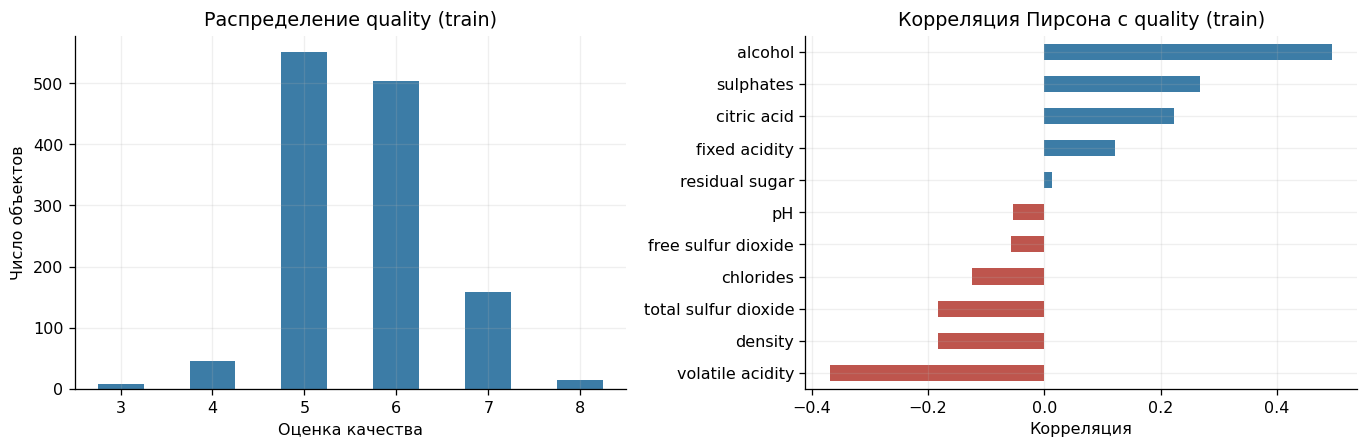

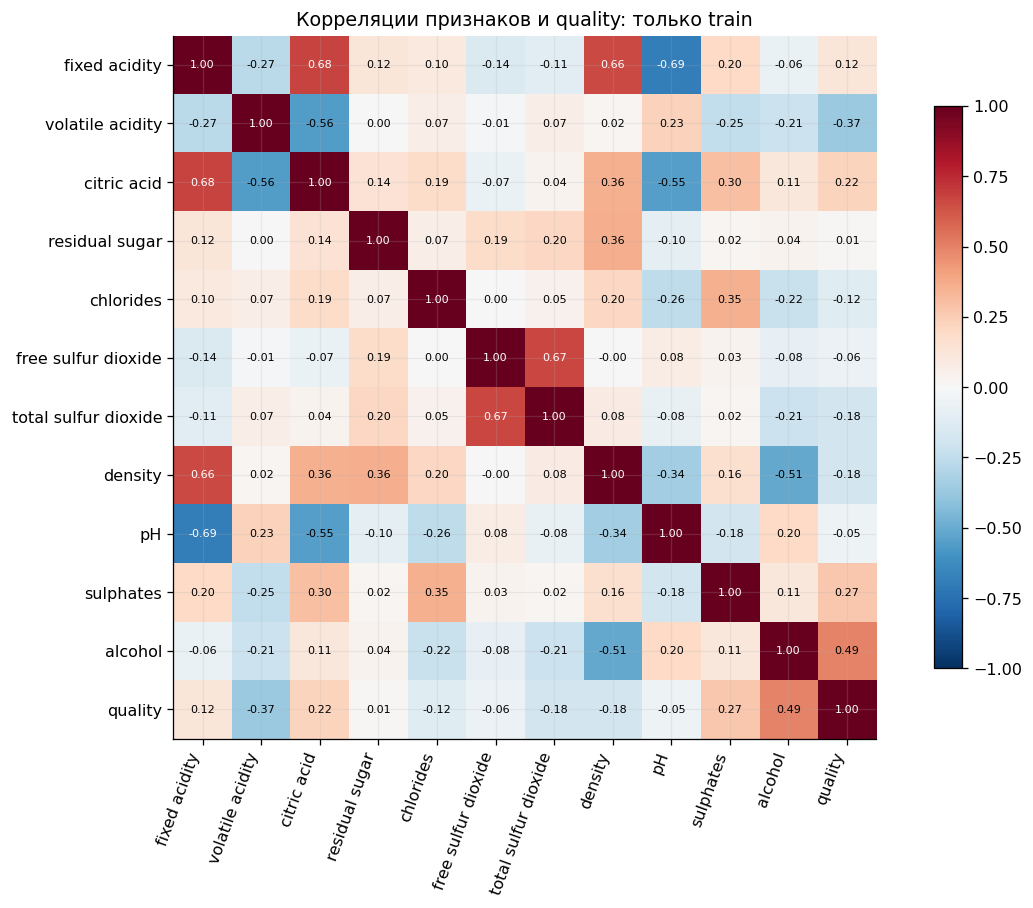

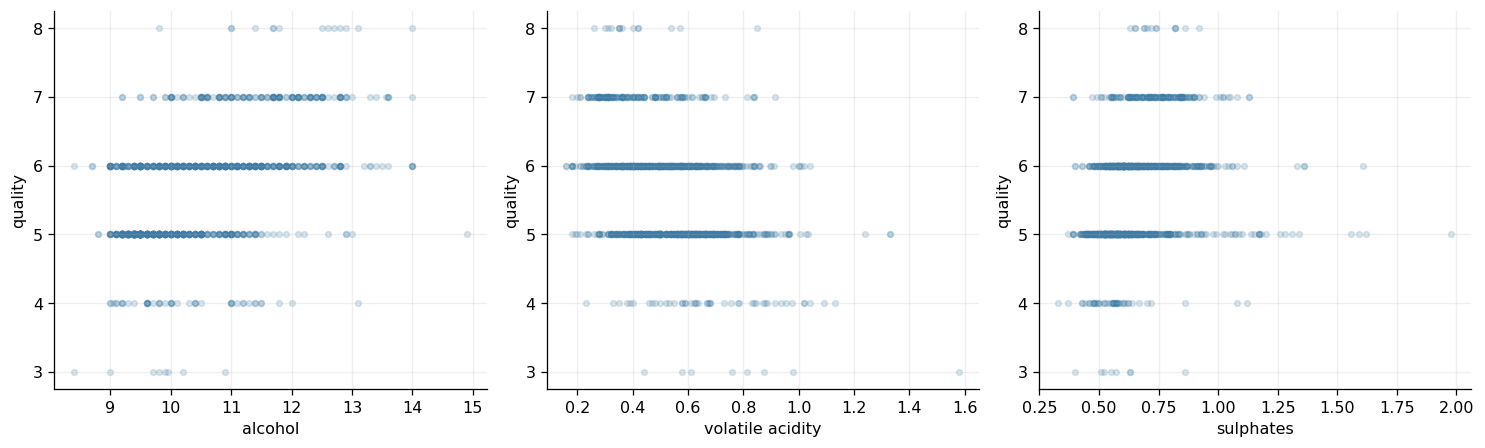

На train 1279 объектов, 11 числовых признаков. Пропусков нет. Оценки 5 и 6 составляют 82.3% train; поэтому низкие и высокие оценки труднее выучить. Сильнейшая положительная линейная связь с quality у alcohol (r=0.495), отрицательная — у volatile acidity (r=-0.368). Это связи в наблюдениях, а не причинные эффекты. Алкоголь и летучая кислотность могут помогать прогнозу, но одной корреляции недостаточно для точного предсказания. Состав вина связан между собой: коррелирующие признаки могут перераспределять веса и важности. Сохраняем все 11 признаков. Редкие значения не удаляем как выбросы: это часть задачи.


,count,mean,std,min,25%,50%,75%,max
fixed acidity,1279.0,8.3344,1.7476,4.6000,7.1000,7.9000,9.3000,15.9000
volatile acidity,1279.0,0.5284,0.1777,0.1600,0.4000,0.5200,0.6400,1.5800
citric acid,1279.0,0.2715,0.1947,0.0000,0.0900,0.2600,0.4300,0.7800
residual sugar,1279.0,2.5400,1.4323,1.2000,1.9000,2.2000,2.6000,15.5000
chlorides,1279.0,0.0878,0.0460,0.0120,0.0700,0.0800,0.0910,0.6110
free sulfur dioxide,1279.0,15.7177,10.3947,1.0000,7.0000,13.0000,21.0000,68.0000
total sulfur dioxide,1279.0,46.0188,32.7089,6.0000,22.0000,37.0000,62.0000,289.0000
density,1279.0,0.9967,0.0019,0.9902,0.9956,0.9968,0.9978,1.0037
pH,1279.0,3.3093,0.1519,2.8600,3.2100,3.3100,3.3900,3.9000
sulphates,1279.0,0.6573,0.1621,0.3300,0.5500,0.6200,0.7300,1.9800


,train_count
quality,
3,8
4,46
5,550
6,503
7,158
8,14


**Вывод по EDA.** На train 1279 объектов, 11 числовых признаков. Пропусков нет. Оценки 5 и 6 составляют 82.3% train; поэтому низкие и высокие оценки труднее выучить. Сильнейшая положительная линейная связь с quality у alcohol (r=0.495), отрицательная — у volatile acidity (r=-0.368). Это связи в наблюдениях, а не причинные эффекты. Алкоголь и летучая кислотность могут помогать прогнозу, но одной корреляции недостаточно для точного предсказания. Состав вина связан между собой: коррелирующие признаки могут перераспределять веса и важности. Сохраняем все 11 признаков. Редкие значения не удаляем как выбросы: это часть задачи.

In [3]:
X, y = (ctx['X_train'], ctx['y_train'])
train = X.assign(quality=y)
desc = train.describe().T
corr = train.corr()
cor_y = corr['quality'].drop('quality').sort_values()
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
y.value_counts().sort_index().plot.bar(ax=axs[0], color='#3c7ca6', rot=0)
axs[0].set(title='Распределение quality (train)', xlabel='Оценка качества', ylabel='Число объектов')
cor_y.plot.barh(ax=axs[1], color=['#be554d' if v < 0 else '#3c7ca6' for v in cor_y])
axs[1].set(title='Корреляция Пирсона с quality (train)', xlabel='Корреляция')
save_figure('01_target_correlations.png')
fig, ax = plt.subplots(figsize=(11, 8))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=70, ha='right')
ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center', fontsize=7, color='white' if abs(corr.iloc[i, j]) > 0.65 else 'black')
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title('Корреляции признаков и quality: только train')
save_figure('02_correlation_matrix.png')
fig, axs = plt.subplots(1, 3, figsize=(13, 4))
for ax, col in zip(axs, ['alcohol', 'volatile acidity', 'sulphates']):
    ax.scatter(X[col], y, s=13, alpha=0.18, color='#3c7ca6')
    ax.set(xlabel=col, ylabel='quality')
save_figure('03_relationships.png')
counts = y.value_counts().sort_index()
positive, negative = (cor_y.idxmax(), cor_y.idxmin())
text = f'На train {len(X)} объектов, 11 числовых признаков. Пропусков нет. Оценки 5 и 6 составляют {counts.reindex([5, 6], fill_value=0).sum() / len(y):.1%} train; поэтому низкие и высокие оценки труднее выучить. Сильнейшая положительная линейная связь с quality у {positive} (r={cor_y[positive]:.3f}), отрицательная — у {negative} (r={cor_y[negative]:.3f}). Это связи в наблюдениях, а не причинные эффекты. Алкоголь и летучая кислотность могут помогать прогнозу, но одной корреляции недостаточно для точного предсказания. Состав вина связан между собой: коррелирующие признаки могут перераспределять веса и важности. Сохраняем все 11 признаков. Редкие значения не удаляем как выбросы: это часть задачи.'
print(text)
description, eda_text = desc, text

display(description)
display(ctx['y_train'].value_counts().sort_index().rename('train_count').to_frame())
display(Markdown('**Вывод по EDA.** ' + eda_text))

## 3. Метрики и baseline

Для $n$ объектов с ответами $y_i$ и прогнозами $\hat y_i$:

$$\operatorname{MAE}=\frac1n\sum_{i=1}^n|y_i-\hat y_i|,\qquad
\operatorname{RMSE}=\sqrt{\frac1n\sum_{i=1}^n(y_i-\hat y_i)^2}.$$

Обе метрики измеряются в **баллах quality**. MAE показывает среднюю абсолютную ошибку.
RMSE — корень из среднего квадрата ошибки: при возведении в квадрат большие отклонения
получают больший вес. Например, для ошибок 0 и 2 MAE=1, RMSE=√2≈1.414.
Поэтому несколько крупных ошибок могут заметно разнести значения этих метрик.
Всегда RMSE ≥ MAE; равенство возможно при одинаковых модулях ошибок.

Для константы $c$ минимизация RMSE эквивалентна минимизации MSE:
$$\frac{d}{dc}\sum_i(y_i-c)^2=2\sum_i(c-y_i)=0
\ \Rightarrow\ c=\overline{y}_{train}.$$
Поэтому baseline — **среднее quality обучающей выборки**, а не test.
Для MAE оптимальной константой была бы медиана, но главная метрика задания — RMSE.
Baseline обучается и проверяется на тех же разбиениях, что и остальные модели.

In [4]:
baseline_constant = float(ctx['y_train'].mean())
print(f'Baseline предсказывает {baseline_constant:.6f} для каждого объекта.')
print('На примере [0, 2]: MAE =', np.mean(np.abs([0, 2])),
      ', RMSE =', np.sqrt(np.mean(np.square([0, 2]))))

Baseline предсказывает 5.624707 для каждого объекта.
На примере [0, 2]: MAE = 1.0 , RMSE = 1.4142135623730951


## 4. Честная валидация и обучение моделей

Внутри train заранее формируем одинаковые **5 grouped folds** для всех моделей.
Копии измерений не пересекают границу обучающей и валидационной части каждого фолда.
Оценка кандидата — среднее RMSE по пяти фолдам. Также сохраняем MAE и стандартное
отклонение RMSE между фолдами; это характеристика разброса, не доверительный интервал.

- **Linear Regression:** `Pipeline(StandardScaler(), LinearRegression())`.
  Средние и масштабы обучаются заново внутри каждого фолда — утечки валидационных
  статистик нет. Масштабирование позволяет содержательно сравнивать коэффициенты.
- **Random Forest Regressor:** 400 деревьев; `max_features ∈ {0.8, 1.0}`,
  `min_samples_leaf ∈ {1, 2}`. Лес усредняет прогнозы деревьев на bootstrap-подвыборках.
- **Gradient Boosting Regressor:** `learning_rate=0.05`,
  `n_estimators ∈ {300, 600}`, `max_depth ∈ {2, 3}`.
  Каждое новое дерево исправляет ошибки текущей композиции.

Обе сетки заданы заранее: по четыре кандидата, то есть по 20 CV-обучений.
Выбор модели делаем **по CV RMSE до получения test-метрик**.
После подбора каждая итоговая модель обучена на всём train.
Настройки и CV-результаты приведены в ноутбуке; `random_state=42` фиксирован.

In [5]:
X, y, groups = (ctx['X_train'], ctx['y_train'], ctx['groups'])
folds = list(GroupKFold(n_splits=5, shuffle=True, random_state=SEED).split(X, y, groups))
for tr, va in folds:
    assert set(groups.iloc[tr]).isdisjoint(set(groups.iloc[va]))
fold_assignment = pd.Series(-1, index=X.index, name='validation_fold')
for k, (_, va) in enumerate(folds):
    fold_assignment.iloc[va] = k
scoring = {'RMSE': 'neg_root_mean_squared_error', 'MAE': 'neg_mean_absolute_error'}
models = {'Baseline': DummyRegressor(strategy='mean'), 'Linear Regression': make_pipeline(StandardScaler(), LinearRegression())}
rows = []
for name, model in models.items():
    scores = cross_validate(model, X, y, cv=folds, scoring=scoring, n_jobs=1)
    rows.append({'model': name, 'CV_RMSE': -scores['test_RMSE'].mean(), 'CV_RMSE_std': scores['test_RMSE'].std(), 'CV_MAE': -scores['test_MAE'].mean()})
    model.fit(X, y)
specs = [('Random Forest', RandomForestRegressor(n_estimators=400, random_state=SEED, n_jobs=1), {'max_features': [0.8, 1.0], 'min_samples_leaf': [1, 2]}), ('Gradient Boosting', GradientBoostingRegressor(random_state=SEED, learning_rate=0.05, loss='squared_error'), {'n_estimators': [300, 600], 'max_depth': [2, 3]})]
best_params = {}
for name, model, params in specs:
    print(f'Подбор {name}: 4 кандидата × 5 фолдов...', flush=True)
    search = GridSearchCV(model, params, cv=folds, scoring=scoring, refit='RMSE', n_jobs=1, error_score='raise', return_train_score=True)
    start = time.perf_counter()
    search.fit(X, y)
    print(f'{name}: CV RMSE={-search.best_score_:.4f}; {time.perf_counter() - start:.1f} с', flush=True)
    idx = search.best_index_
    rows.append({'model': name, 'CV_RMSE': -search.best_score_, 'CV_RMSE_std': search.cv_results_['std_test_RMSE'][idx], 'CV_MAE': -search.cv_results_['mean_test_MAE'][idx]})
    models[name] = search.best_estimator_
    best_params[name] = search.best_params_
validation = pd.DataFrame(rows).set_index('model')
winner = validation['CV_RMSE'].idxmin()
print('Выбрана до оценки на test:', winner)

display(validation)
import json
display({'winner': winner, 'best_params': best_params})
display(Markdown(f'**Модель зафиксирована до test:** {winner}.'))

Подбор Random Forest: 4 кандидата × 5 фолдов...


Random Forest: CV RMSE=0.6351; 56.6 с


Подбор Gradient Boosting: 4 кандидата × 5 фолдов...


Gradient Boosting: CV RMSE=0.6420; 25.4 с


Выбрана до оценки на test: Random Forest


,CV_RMSE,CV_RMSE_std,CV_MAE
model,,,
Baseline,0.8111,0.0325,0.6878
Linear Regression,0.6624,0.0263,0.5103
Random Forest,0.6351,0.0299,0.4815
Gradient Boosting,0.6420,0.0296,0.4898


{'winner': 'Random Forest',
 'best_params': {'Random Forest': {'max_features': 0.8, 'min_samples_leaf': 1},
  'Gradient Boosting': {'max_depth': 2, 'n_estimators': 300}}}

**Модель зафиксирована до test:** Random Forest.

## 5. Финальная оценка на едином test

Только теперь получаем test-прогнозы всех зафиксированных моделей.
Основные столбцы итоговой таблицы — **RMSE и MAE**. Дополнительно приводим train RMSE
и CV-оценки, чтобы видеть переобучение и устойчивость результата.
Победителя не меняем по test и не перебираем random_state ради прохождения порога.
Выбранная модель в переменной `models[winner]` обучена только на train.

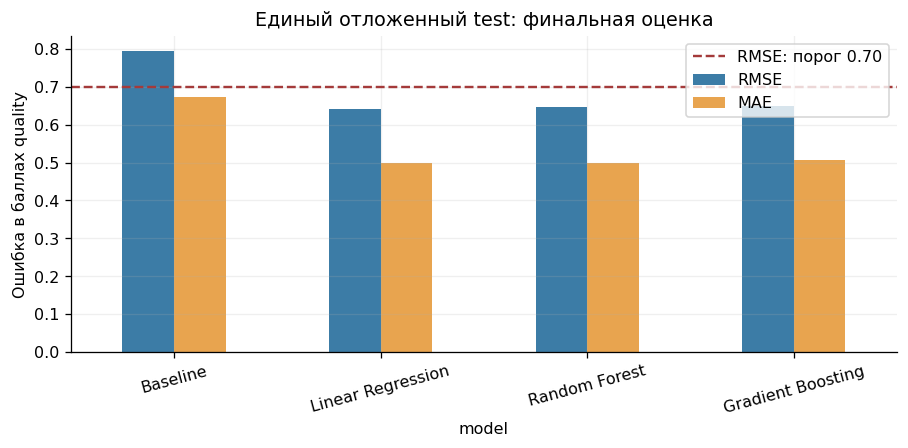

Победитель по CV: Random Forest
Его test RMSE = 0.6454; MAE = 0.4999. Порог 0.70: пройден


,RMSE,MAE,train_RMSE,CV_RMSE,CV_RMSE_std,CV_MAE
model,,,,,,
Baseline,0.7955,0.6719,0.8103,0.8111,0.0325,0.6878
Linear Regression,0.6426,0.4997,0.6473,0.6624,0.0263,0.5103
Random Forest,0.6454,0.4999,0.2080,0.6351,0.0299,0.4815
Gradient Boosting,0.6493,0.5057,0.5334,0.6420,0.0296,0.4898


**Проверка локального порога для выбранной модели:** RMSE=0.6454; порог < 0.70 пройден.

In [6]:
rows, predictions = ([], {})
y = ctx['y_test']
for name, model in models.items():
    pred = model.predict(ctx['X_test'])
    predictions[name] = pred
    rows.append({'model': name, 'RMSE': root_mean_squared_error(y, pred), 'MAE': mean_absolute_error(y, pred), 'train_RMSE': root_mean_squared_error(ctx['y_train'], model.predict(ctx['X_train']))})
metrics = pd.DataFrame(rows).set_index('model').join(validation)
preds = pd.DataFrame(predictions, index=y.index).rename_axis('row_id')
preds.insert(0, 'quality', y)
fig, ax = plt.subplots(figsize=(8, 4))
metrics[['RMSE', 'MAE']].plot.bar(ax=ax, color=['#3c7ca6', '#e8a44f'], rot=15)
ax.axhline(0.7, color='#a43a3a', linestyle='--', label='RMSE: порог 0.70')
ax.set(ylabel='Ошибка в баллах quality', title='Единый отложенный test: финальная оценка')
ax.legend(loc='upper right')
save_figure('04_metrics.png')
print('Победитель по CV:', winner)
print(f"Его test RMSE = {metrics.loc[winner, 'RMSE']:.4f}; MAE = {metrics.loc[winner, 'MAE']:.4f}. Порог 0.70: " + ('пройден' if metrics.loc[winner, 'RMSE'] < 0.7 else 'не пройден'))

display(metrics)
display(Markdown(
    f'**Проверка локального порога для выбранной модели:** '
    f'RMSE={metrics.loc[winner, "RMSE"]:.4f}; '
    + ('порог < 0.70 пройден.' if metrics.loc[winner, 'RMSE'] < .70 else 'порог < 0.70 не пройден.')
))

## 6. Коэффициенты и важность признаков

Коэффициенты линейной модели относятся к стандартизованным признакам: коэффициент
показывает изменение прогноза при увеличении признака на одно train-стандартное отклонение
при фиксированных остальных признаках. По модулю сравниваем именно такие коэффициенты,
а не веса исходных величин разных единиц измерения.

У леса и бустинга получаем `feature_importances_` (MDI) и показываем их на графиках.
Сравнивать знак линейного коэффициента с MDI напрямую нельзя: MDI не имеет направления.
Важности рассчитываются по обученным на train моделям и не используют test-ответы.

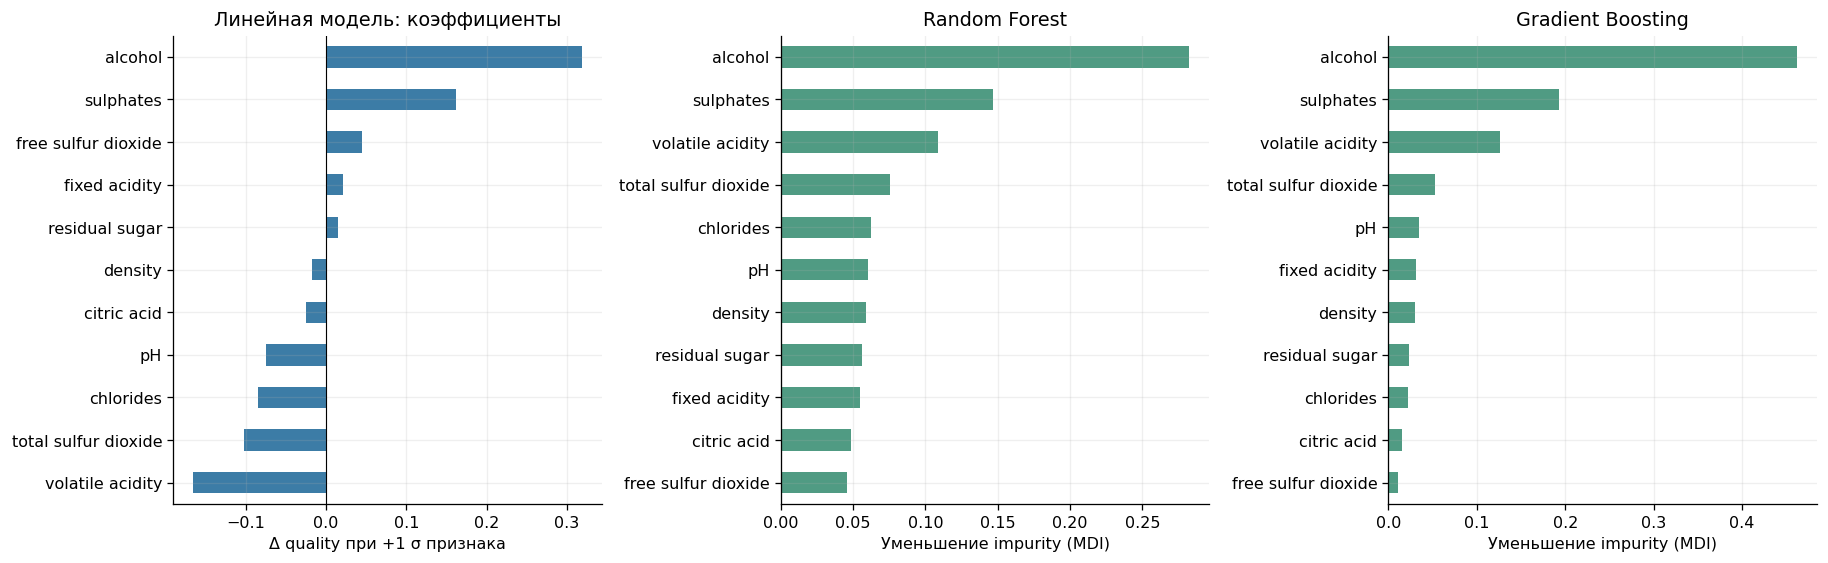

Топ-3 признака: {"Linear Regression": ["alcohol", "volatile acidity", "sulphates"], "Random Forest": ["alcohol", "sulphates", "volatile acidity"], "Gradient Boosting": ["alcohol", "sulphates", "volatile acidity"]}
Коэффициенты относятся к стандартизованным признакам; это условные связи при фиксированных остальных X. Для обычной линейной регрессии масштабирование почти не меняет предсказания, но позволяет сравнивать коэффициенты. Лес и бустинг не требуют стандартизации. MDI показывает вклад разбиений в уменьшение ошибки на train, не направление эффекта. MDI может предпочитать признаки с большим числом порогов; коррелирующие X делят важность. Причинный вывод невозможен: это наблюдательные данные без контролируемого вмешательства.


,standardized_coefficient
alcohol,0.3192
volatile acidity,-0.1661
sulphates,0.1619
total sulfur dioxide,-0.1019
chlorides,-0.0845
pH,-0.0752
free sulfur dioxide,0.0446
citric acid,-0.0244
fixed acidity,0.0207
density,-0.0179


,Random Forest,Gradient Boosting
alcohol,0.2823,0.4617
sulphates,0.1469,0.1924
volatile acidity,0.1084,0.1267
total sulfur dioxide,0.0754,0.0532
chlorides,0.0626,0.0217
pH,0.0604,0.0340
density,0.0589,0.0296
residual sugar,0.0560,0.0232
fixed acidity,0.0550,0.0315
citric acid,0.0484,0.0149


**Linear Regression:** топ-3 — alcohol, volatile acidity, sulphates. Совпадение с топ-3 EDA по |корреляции|: alcohol, sulphates, volatile acidity.

**Random Forest:** топ-3 — alcohol, sulphates, volatile acidity. Совпадение с топ-3 EDA по |корреляции|: alcohol, sulphates, volatile acidity.

**Gradient Boosting:** топ-3 — alcohol, sulphates, volatile acidity. Совпадение с топ-3 EDA по |корреляции|: alcohol, sulphates, volatile acidity.

**Общие лидеры двух ансамблей:** alcohol, sulphates, volatile acidity.

Различия ожидаемы: корреляция измеряет отдельную линейную связь, коэффициент — условную линейную связь, а MDI учитывает пороги и взаимодействия. Взаимосвязанные признаки могут делить важность, поэтому рейтинги не обязаны совпадать.

In [7]:
cols = ctx['X_train'].columns
coefs = pd.Series(models['Linear Regression'].named_steps['linearregression'].coef_, index=cols, name='standardized_coefficient')
imps = pd.DataFrame({name: models[name].feature_importances_ for name in ['Random Forest', 'Gradient Boosting']}, index=cols)
fig, axs = plt.subplots(1, 3, figsize=(16, 5))
coefs.sort_values().plot.barh(ax=axs[0], color='#3c7ca6')
axs[0].axvline(0, color='black', linewidth=0.7)
axs[0].set(title='Линейная модель: коэффициенты', xlabel='Δ quality при +1 σ признака')
for ax, name in zip(axs[1:], imps.columns):
    imps[name].sort_values().plot.barh(ax=ax, color='#509b83')
    ax.set(title=name, xlabel='Уменьшение impurity (MDI)')
save_figure('05_importance.png')
top = {'Linear Regression': list(coefs.abs().nlargest(3).index), **{name: list(imps[name].nlargest(3).index) for name in imps.columns}}
print('Топ-3 признака:', json.dumps(top, ensure_ascii=False))
print('Коэффициенты относятся к стандартизованным признакам; это условные связи при фиксированных остальных X. Для обычной линейной регрессии масштабирование почти не меняет предсказания, но позволяет сравнивать коэффициенты. Лес и бустинг не требуют стандартизации. MDI показывает вклад разбиений в уменьшение ошибки на train, не направление эффекта. MDI может предпочитать признаки с большим числом порогов; коррелирующие X делят важность. Причинный вывод невозможен: это наблюдательные данные без контролируемого вмешательства.')
coefficients, importances = coefs, imps

display(coefficients.reindex(coefficients.abs().sort_values(ascending=False).index).to_frame())
display(importances.sort_values('Random Forest', ascending=False))
corr = ctx['X_train'].corrwith(ctx['y_train'])
corr_top = set(corr.abs().nlargest(3).index)
lines = []
for name, names in top.items():
    overlap = sorted(set(names) & corr_top)
    lines.append(f'**{name}:** топ-3 — {", ".join(names)}. '
                 f'Совпадение с топ-3 EDA по |корреляции|: {", ".join(overlap) or "нет"}.')
common = sorted(set(top['Random Forest']) & set(top['Gradient Boosting']))
lines.append('**Общие лидеры двух ансамблей:** ' + (', '.join(common) or 'нет') + '.')
lines.append('Различия ожидаемы: корреляция измеряет отдельную линейную связь, коэффициент — '
             'условную линейную связь, а MDI учитывает пороги и взаимодействия. '
             'Взаимосвязанные признаки могут делить важность, поэтому рейтинги не обязаны совпадать.')
display(Markdown('\n\n'.join(lines)))

**Можно ли считать важность причинным эффектом?** Нет. Модель описывает статистические
закономерности наблюдательной выборки. Возможны смешивающие факторы и связанные признаки;
изменение одного вещества может менять другие свойства. Высокая важность `alcohol`,
например, не доказывает, что добавление алкоголя улучшит качество. Нужен отдельный
причинный дизайн или эксперимент. MDI также может предпочитать признаки с большим
числом возможных порогов разбиения, а коррелирующие признаки могут замещать друг друга.

## 7. Анализ ошибок выбранной по CV модели

Остаток определяем как `quality − prediction`: положительный остаток означает
недооценку качества. Строим распределение остатков, сопоставляем истинные и прогнозные
значения, рассчитываем MAE/RMSE отдельно для каждого представленного значения quality.
Указываем размеры групп в train и test, чтобы не переинтерпретировать редкие оценки.

Для трёх самых больших ошибок сравниваем объект с пятью ближайшими объектами train
в стандартизованном пространстве. Это диагностический приём, а не дополнительная модель.
Причины ошибок формулируем как гипотезы; истинные скрытые свойства вина нам неизвестны.

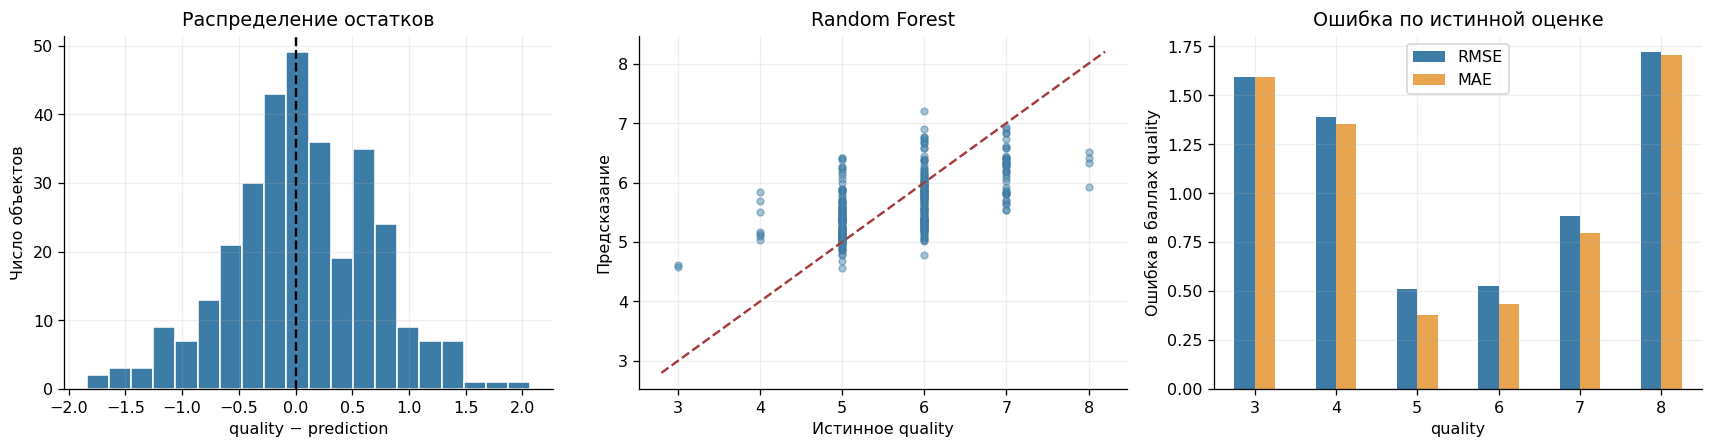

Строка 1403: истинное quality=8, прогноз=5.93, абсолютная ошибка=2.07. Оценки 5 ближайших train-объектов: [5, 5, 6, 5, 7]; сильнейшие отклонения от train-средних: sulphates: +2.7σ, free sulfur dioxide: -1.2σ. Возможное объяснение — похожие химические характеристики соответствуют другим экспертным оценкам; также могут влиять неучтённые свойства вина и шум оценивания. Это гипотеза, а не доказанная причина ошибки.
Строка 1484: истинное quality=4, прогноз=5.84, абсолютная ошибка=1.84. Оценки 5 ближайших train-объектов: [6, 6, 6, 6, 6]; сильнейшие отклонения от train-средних: volatile acidity: +2.1σ, pH: +1.5σ. Возможное объяснение — похожие химические характеристики соответствуют другим экспертным оценкам; также могут влиять неучтённые свойства вина и шум оценивания. Это гипотеза, а не доказанная причина ошибки.
Строка 876: истинное quality=4, прогноз=5.69, абсолютная ошибка=1.69. Оценки 5 ближайших train-объектов: [6, 6, 6, 6, 6]; сильнейшие отклонения от train-средних: citric acid: -1.4σ

,n_test,n_train,mean_prediction,MAE,RMSE
quality,,,,,
3,2,8,4.5938,1.5938,1.5938
4,7,46,5.3536,1.3536,1.3857
5,131,550,5.3465,0.3769,0.5081
6,135,503,5.7370,0.4332,0.5259
7,41,158,6.2040,0.7960,0.8810
8,4,14,6.2969,1.7031,1.7177


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,prediction,residual,absolute_error
row_id,,,,,,,,,,,,,,,
1403,7.2,0.330,0.33,1.70,0.061,3.0,13.0,0.9960,3.23,1.10,10.0,8,5.9300,2.0700,2.0700
1484,6.8,0.910,0.06,2.00,0.060,4.0,11.0,0.9959,3.53,0.64,10.9,4,5.8425,-1.8425,1.8425
876,7.1,0.470,0.00,2.20,0.067,7.0,14.0,0.9952,3.40,0.58,10.9,4,5.6875,-1.6875,1.6875
1449,7.2,0.380,0.31,2.00,0.056,15.0,29.0,0.9947,3.23,0.76,11.3,8,6.3200,1.6800,1.6800
899,8.3,1.020,0.02,3.40,0.084,6.0,11.0,0.9989,3.48,0.49,11.0,3,4.6100,-1.6100,1.6100
455,11.3,0.620,0.67,5.20,0.086,6.0,19.0,0.9988,3.22,0.69,13.4,8,6.4200,1.5800,1.5800
690,7.4,1.185,0.00,4.25,0.097,5.0,14.0,0.9966,3.63,0.54,10.7,3,4.5775,-1.5775,1.5775
151,9.2,0.520,1.00,3.40,0.610,32.0,69.0,0.9996,2.74,2.00,9.4,4,5.4975,-1.4975,1.4975
1269,5.5,0.490,0.03,1.80,0.044,28.0,87.0,0.9908,3.50,0.82,14.0,8,6.5175,1.4825,1.4825


Строка 1403: истинное quality=8, прогноз=5.93, абсолютная ошибка=2.07. Оценки 5 ближайших train-объектов: [5, 5, 6, 5, 7]; сильнейшие отклонения от train-средних: sulphates: +2.7σ, free sulfur dioxide: -1.2σ. Возможное объяснение — похожие химические характеристики соответствуют другим экспертным оценкам; также могут влиять неучтённые свойства вина и шум оценивания. Это гипотеза, а не доказанная причина ошибки.

Строка 1484: истинное quality=4, прогноз=5.84, абсолютная ошибка=1.84. Оценки 5 ближайших train-объектов: [6, 6, 6, 6, 6]; сильнейшие отклонения от train-средних: volatile acidity: +2.1σ, pH: +1.5σ. Возможное объяснение — похожие химические характеристики соответствуют другим экспертным оценкам; также могут влиять неучтённые свойства вина и шум оценивания. Это гипотеза, а не доказанная причина ошибки.

Строка 876: истинное quality=4, прогноз=5.69, абсолютная ошибка=1.69. Оценки 5 ближайших train-объектов: [6, 6, 6, 6, 6]; сильнейшие отклонения от train-средних: citric acid: -1.4σ, total sulfur dioxide: -1.0σ. Возможное объяснение — похожие химические характеристики соответствуют другим экспертным оценкам; также могут влиять неучтённые свойства вина и шум оценивания. Это гипотеза, а не доказанная причина ошибки.

Редкие крайние оценки представлены слабо, а минимум квадратичной ошибки тяготеет к условному среднему. Поэтому модель может завышать низкие и занижать высокие оценки. Это следует проверять по таблице, а не предполагать одинаковую точность для всех групп. После этого анализа параметры и состав данных не меняются.

In [8]:
y = ctx['y_test']
pred = predictions[winner]
errors = ctx['X_test'].copy()
errors['quality'] = y
errors['prediction'] = pred
errors['residual'] = y - pred
errors['absolute_error'] = abs(y - pred)
errors.index.name = 'row_id'
worst = errors.sort_values('absolute_error', ascending=False).head(10)
grouped = []
for q, group in errors.groupby('quality'):
    grouped.append({'quality': int(q), 'n_test': len(group), 'n_train': int((ctx['y_train'] == q).sum()), 'mean_prediction': group['prediction'].mean(), 'MAE': group['absolute_error'].mean(), 'RMSE': root_mean_squared_error(group['quality'], group['prediction'])})
by_quality = pd.DataFrame(grouped).set_index('quality')
fig, axs = plt.subplots(1, 3, figsize=(15, 4))
axs[0].hist(errors['residual'], bins=20, color='#3c7ca6', edgecolor='white')
axs[0].axvline(0, color='black', linestyle='--')
axs[0].set(title='Распределение остатков', xlabel='quality − prediction', ylabel='Число объектов')
axs[1].scatter(y, pred, alpha=0.45, s=18, color='#3c7ca6')
lim = [min(y.min(), pred.min()) - 0.2, max(y.max(), pred.max()) + 0.2]
axs[1].plot(lim, lim, '--', color='#a43a3a')
axs[1].set(xlabel='Истинное quality', ylabel='Предсказание', title=winner)
by_quality[['RMSE', 'MAE']].plot.bar(ax=axs[2], rot=0, color=['#3c7ca6', '#e8a44f'])
axs[2].set(title='Ошибка по истинной оценке', ylabel='Ошибка в баллах quality')
save_figure('06_errors.png')
scaler = StandardScaler().fit(ctx['X_train'])
scaled_train = scaler.transform(ctx['X_train'])
notes = []
for row_id, row in worst.head(3).iterrows():
    sample = ctx['X_test'].loc[[row_id]]
    d = np.linalg.norm(scaled_train - scaler.transform(sample), axis=1)
    near = np.argsort(d)[:5]
    near_y = ctx['y_train'].iloc[near].tolist()
    z = pd.Series(scaler.transform(sample)[0], index=sample.columns)
    unusual = ', '.join((f'{k}: {v:+.1f}σ' for k, v in z.reindex(z.abs().nlargest(2).index).items()))
    note = f"Строка {row_id}: истинное quality={row['quality']:.0f}, прогноз={row['prediction']:.2f}, абсолютная ошибка={row['absolute_error']:.2f}. Оценки 5 ближайших train-объектов: {near_y}; сильнейшие отклонения от train-средних: {unusual}. Возможное объяснение — похожие химические характеристики соответствуют другим экспертным оценкам; также могут влиять неучтённые свойства вина и шум оценивания. Это гипотеза, а не доказанная причина ошибки."
    notes.append(note)
    print(note)
print('Редкие оценки слабее представлены в обучении, поэтому при квадратичной функции потерь прогнозы тяготеют к более частым средним значениям. Для малых групп метрики нестабильны; смотрите n_test и n_train. Этот анализ выполнен после фиксации модели и не используется для её донастройки.')
worst_errors, errors_by_quality, error_notes = worst, by_quality, notes

display(errors_by_quality)
display(worst_errors)
for note in error_notes:
    display(Markdown(note))
display(Markdown(
    'Редкие крайние оценки представлены слабо, а минимум квадратичной ошибки тяготеет '
    'к условному среднему. Поэтому модель может завышать низкие и занижать высокие '
    'оценки. Это следует проверять по таблице, а не предполагать одинаковую точность для всех групп. '
    'После этого анализа параметры и состав данных не меняются.'
))

## 8. Итог и ограничения

Сравниваем модели с baseline и объясняем результат с учётом свойств алгоритмов.
Выбор победителя основан на CV, финальные test-метрики являются проверкой этого решения.

In [9]:
baseline = metrics.loc['Baseline', 'RMSE']
text = f"Выбранная на grouped CV модель: {winner}. На test RMSE={metrics.loc[winner, 'RMSE']:.4f}, MAE={metrics.loc[winner, 'MAE']:.4f}; RMSE baseline={baseline:.4f}. Снижение RMSE относительно baseline: {1 - metrics.loc[winner, 'RMSE'] / baseline:.1%}. Модели, превзошедшие baseline по test RMSE: " + ', '.join(metrics.index[(metrics['RMSE'] < baseline) & (metrics.index != 'Baseline')]) + '. Линейная модель ограничена аддитивной линейной зависимостью. Деревья могут учитывать пороги и взаимодействия физико-химических признаков. Лес усредняет деревья и снижает их дисперсию; бустинг последовательно исправляет ошибки и зависит от глубины и числа итераций. Нелинейность позволяет ансамблям улучшать CV-качество, но один holdout не доказывает универсальное превосходство алгоритма. Значение CV для победителя оптимистично из-за подбора параметров; независимый test нужен для финальной оценки. Порог 0.70 относится здесь только к локальному test. Скрытая выборка преподавателя недоступна, её результат не гарантируется. Модель прогнозирует непрерывное число: округление и clipping не применялись.'
test_leader = metrics['RMSE'].idxmin()
text += f" Минимальный test RMSE в итоговой таблице у {test_leader}: {metrics.loc[test_leader, 'RMSE']:.4f}. "
if test_leader != winner:
    text += f"Он отличается от победителя CV; разница на test {metrics.loc[winner, 'RMSE'] - metrics.loc[test_leader, 'RMSE']:.4f} балла. Это показывает зависимость ранжирования от выборки, а не основание переопределять выбранную модель по test. "
text += f"У леса train RMSE={metrics.loc['Random Forest', 'train_RMSE']:.4f}, test RMSE={metrics.loc['Random Forest', 'RMSE']:.4f}: заметный разрыв указывает на подгонку к обучающей выборке. У линейной модели train RMSE={metrics.loc['Linear Regression', 'train_RMSE']:.4f}, test RMSE={metrics.loc['Linear Regression', 'RMSE']:.4f}; близкие значения согласуются с меньшей сложностью этой модели."
print(text)
summary = text

display(Markdown(summary))
display(Markdown(
    '**Лидеры признаков:** ' + '; '.join(f'{k}: {", ".join(v)}' for k,v in top.items()) + '.\n\n'
    '**Ограничения:** работа посвящена красному Vinho Verde; перенос на белое вино, другие '
    'регионы и новые партии не проверялся. Группировка защищает от одинаковых X, но '
    'не гарантирует независимость скрытых партий. Экспертная оценка шумная, крайние '
    'значения редки, test имеет ограниченный размер. Результат на скрытом тесте неизвестен.'
))

Выбранная на grouped CV модель: Random Forest. На test RMSE=0.6454, MAE=0.4999; RMSE baseline=0.7955. Снижение RMSE относительно baseline: 18.9%. Модели, превзошедшие baseline по test RMSE: Linear Regression, Random Forest, Gradient Boosting. Линейная модель ограничена аддитивной линейной зависимостью. Деревья могут учитывать пороги и взаимодействия физико-химических признаков. Лес усредняет деревья и снижает их дисперсию; бустинг последовательно исправляет ошибки и зависит от глубины и числа итераций. Нелинейность позволяет ансамблям улучшать CV-качество, но один holdout не доказывает универсальное превосходство алгоритма. Значение CV для победителя оптимистично из-за подбора параметров; независимый test нужен для финальной оценки. Порог 0.70 относится здесь только к локальному test. Скрытая выборка преподавателя недоступна, её результат не гарантируется. Модель прогнозирует непрерывное число: округление и clipping не применялись. Минимальный test RMSE в итоговой таблице у Linear Regr

Выбранная на grouped CV модель: Random Forest. На test RMSE=0.6454, MAE=0.4999; RMSE baseline=0.7955. Снижение RMSE относительно baseline: 18.9%. Модели, превзошедшие baseline по test RMSE: Linear Regression, Random Forest, Gradient Boosting. Линейная модель ограничена аддитивной линейной зависимостью. Деревья могут учитывать пороги и взаимодействия физико-химических признаков. Лес усредняет деревья и снижает их дисперсию; бустинг последовательно исправляет ошибки и зависит от глубины и числа итераций. Нелинейность позволяет ансамблям улучшать CV-качество, но один holdout не доказывает универсальное превосходство алгоритма. Значение CV для победителя оптимистично из-за подбора параметров; независимый test нужен для финальной оценки. Порог 0.70 относится здесь только к локальному test. Скрытая выборка преподавателя недоступна, её результат не гарантируется. Модель прогнозирует непрерывное число: округление и clipping не применялись. Минимальный test RMSE в итоговой таблице у Linear Regression: 0.6426. Он отличается от победителя CV; разница на test 0.0028 балла. Это показывает зависимость ранжирования от выборки, а не основание переопределять выбранную модель по test. У леса train RMSE=0.2080, test RMSE=0.6454: заметный разрыв указывает на подгонку к обучающей выборке. У линейной модели train RMSE=0.6473, test RMSE=0.6426; близкие значения согласуются с меньшей сложностью этой модели.

**Лидеры признаков:** Linear Regression: alcohol, volatile acidity, sulphates; Random Forest: alcohol, sulphates, volatile acidity; Gradient Boosting: alcohol, sulphates, volatile acidity.

**Ограничения:** работа посвящена красному Vinho Verde; перенос на белое вино, другие регионы и новые партии не проверялся. Группировка защищает от одинаковых X, но не гарантирует независимость скрытых партий. Экспертная оценка шумная, крайние значения редки, test имеет ограниченный размер. Результат на скрытом тесте неизвестен.

## 9. Как запустить

Рядом должны лежать только два файла:

- `lab01.ipynb` — весь код и результаты;
- `winequality-red.csv` — исходные данные.

На этом компьютере окружение уже установлено. В PowerShell:

```powershell
cd C:\ML\lab1
.\.venv\Scripts\python.exe -m jupyterlab lab01.ipynb
```

В открывшемся JupyterLab выберите **Kernel → Restart Kernel and Run All Cells**.
Полное выполнение занимает около двух минут. Все таблицы и графики появятся под ячейками.
После выполнения сохраните ноутбук через **Ctrl+S**, чтобы результаты остались внутри файла.
Для просмотра уже выполненного ноутбука пересчитывать его не обязательно.

На другом компьютере сначала установите Python 3.12+ и библиотеки:

```powershell
python -m pip install numpy==2.4.4 pandas==3.0.1 matplotlib==3.10.9 scikit-learn==1.8.0 jupyterlab==4.5.6
python -m jupyterlab lab01.ipynb
```

Также можно открыть ноутбук в VS Code с расширением Jupyter и выбрать Python с указанными
библиотеками. Интернет нужен только для первоначальной установки зависимостей.
Сам эксперимент читает локальный CSV и не требует сети.
